# Group synthesis: the full story

Each dataset was analysed in its own notebook. This notebook does not redo those analyses: it connects their results, checks the links between datasets directly in the data, and reconstructs the story hidden in the data.

*Use of generative AI: this notebook was written with the help of Claude (Anthropic), based on the conclusions of the group's notebooks. The links between datasets were recomputed here and the results reviewed. Each notebook states its own use of AI (section 5).*

## 1. The notebooks of the repository

| Dataset | Notebook(s) | What it brings to the story |
|---|---|---|
| `public_records` | `public_records/public_records.ipynb` | Horizon's access to natural sites, the investigative documents, the abnormal identities |
| `ecology` | `ecology/ecology.ipynb` | the drop in bat counts after each Horizon access |
| `logistics` | `logistics/01_cleaning.ipynb`, `logistics/02_analysis.ipynb` | the biological lots that vanish at Meridian, the stock withdrawals at the Asterion clinics |
| `health` | `health/01_cleaning.ipynb`, `health/02_analysis.ipynb`, `health/03_report.ipynb` | the executives rejuvenated by `MRP-42`, the 10 patients with a non-human physiology |

The notebooks are run from the `notebooks/` folder. This one reads the raw data of `public_records`, `ecology` and `health` (only dates and a few numbers are converted), and the logistics files cleaned by `logistics/01_cleaning.ipynb`.

In [1]:
import re
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Public records
access = pd.read_csv("../data/public_records/site_access_case_events.csv")
access["event_time"] = pd.to_datetime(access["event_time"], format="mixed")
access["activity"] = access["activity"].str.lower()
documents = pd.read_csv("../data/public_records/public_and_investigative_documents.csv").set_index("document_id")
memos = pd.read_csv("../data/public_records/institutional_memos.csv").set_index("document_id")
filings = pd.read_csv("../data/public_records/officer_filings.csv")
licenses = pd.read_csv("../data/public_records/licensed_professionals.csv")
facilities = pd.read_csv("../data/public_records/licensed_facilities.csv")

# Ecology
bats = pd.read_csv("../data/ecology/bat_surveys.csv", dtype=str)
climate = pd.read_csv("../data/ecology/environmental_monthly.csv", dtype=str)

# Health (one patient appears twice, identically: we keep a single row)
patients = pd.read_csv("../data/health/patient_administration.csv").drop_duplicates().set_index("patient_number")
procedures = pd.read_csv("../data/health/clinical_procedures.csv")
procedures["day"] = pd.to_datetime(procedures["performed_time"], format="mixed").dt.normalize()
observations = pd.read_csv("../data/health/clinical_observations.csv", dtype=str)
notes = pd.read_csv("../data/health/clinical_notes.csv").set_index("document_id")

# Logistics (cleaned files)
shipments = pd.read_csv("../data/logistics/clean/shipments_clean.csv", parse_dates=["dispatch_time", "arrival_time"])
adjustments = pd.read_csv("../data/logistics/clean/inventory_adjustments_clean.csv", parse_dates=["adjustment_date"])
stocks = pd.read_csv("../data/logistics/clean/inventory_month_end_clean.csv", parse_dates=["reporting_month"])
sites = pd.read_csv("../data/logistics/clean/erp_facilities_clean.csv").set_index("facility_code")
partners = pd.read_csv("../data/logistics/clean/erp_business_partners_clean.csv").set_index("partner_code")


# Returns the first sentence of a text that contains a given word
def sentence(text, word):
    for chunk in re.split(r"(?<=[.!?])\s+|\n+|\s{3,}", text):
        if word.lower() in chunk.lower():
            return chunk.strip()


# Converts a text column to numbers (decimal commas, attached units)
def number(column):
    return pd.to_numeric(column.astype(str).str.replace(",", ".").str.extract(r"(-?\d+\.?\d*)")[0], errors="coerce")

## 2. The story, step by step

### Step 1: night-time access to caves, then a drop in bats (public records → ecology)

In [2]:
# The access cases of Horizon Field Research Cooperative
horizon = access[access["requesting_organization_name"] == "Horizon Field Research Cooperative"]
print("Horizon access cases:", horizon["access_case_number"].nunique(), "out of", access["access_case_number"].nunique())
print("Natural sites visited:", horizon["site_code"].nunique(), sorted(horizon["site_code"].unique()))
print("Start hour:", horizon.loc[horizon["activity"] == "access_started", "event_time"].dt.hour.value_counts().to_dict(),
      "| end hour:", horizon.loc[horizon["activity"] == "access_completed", "event_time"].dt.hour.value_counts().to_dict())

Horizon access cases: 18 out of 60
Natural sites visited: 8 ['AVL-MAR', 'AVL-ORR', 'AVL-VEL', 'KNT-KES', 'KNT-LUM', 'KNT-SEN', 'TMB-NAC', 'TMB-PEL']
Start hour: {18: 18} | end hour: {3: 18}


In [3]:
# Bat surveys: one survey per site and per month
bats["month"] = pd.to_datetime(bats["survey_start"], format="mixed").dt.to_period("M")
bats["count"] = number(bats["observed_bat_count"])
bats = bats.drop_duplicates(["site_code", "month"])

# Normal level: the site's median for the same calendar month (this removes seasonality)
bats["normal"] = bats.groupby(["site_code", bats["month"].dt.month])["count"].transform("median")
bats["log_gap"] = np.log((bats["count"] + 1) / (bats["normal"] + 1))
surveys = bats.set_index(["site_code", "month"])["log_gap"]


# Mean gap to normal during the 2 months following an access
def after_access(site, month):
    values = [surveys.get((site, month + k)) for k in (1, 2)]
    values = [v for v in values if v is not None and not pd.isna(v)]
    return np.mean(values) if values else np.nan


starts = access[access["activity"] == "access_started"].copy()
starts["month"] = starts["event_time"].dt.to_period("M")
starts["gap_after"] = [after_access(s, m) for s, m in zip(starts["site_code"], starts["month"])]
starts["organization"] = np.where(starts["requesting_organization_name"] == "Horizon Field Research Cooperative", "Horizon", "others")

# How many Horizon accesses are followed by a drop
drops = starts.loc[starts["organization"] == "Horizon", "gap_after"].dropna()
print("Horizon accesses followed by a drop:", (drops < 0).sum(), "out of", len(drops))

# Mean change in the number of bats after the accesses, in %
result = starts.dropna(subset=["gap_after"]).groupby("organization")["gap_after"].agg(accesses="size", mean_gap="mean")
result["change_%"] = ((np.exp(result["mean_gap"]) - 1) * 100).round(0)
result

Horizon accesses followed by a drop: 14 out of 14


,accesses,mean_gap,change_%
organization,,,
Horizon,14,-0.885931,-59.0
others,26,-0.048680,-5.0


Horizon accounts for 18 of the 60 access cases, always on the same 8 natural sites, and its accesses take place at night, from 6 pm to 3 am. In the two months following **each** of its 14 observable accesses, the number of bats falls below the seasonal norm: **about 59% on average**. After the accesses of the other organisations, nothing changes. This matches the result of `ecology/ecology.ipynb` (section 10), which confirms it with a placebo test (p ≈ 0.0005) and shows that other species, measuring devices and weather are not responsible.

### Step 2: a refrigerated parcel 6 h after each access (public records → logistics)

In [4]:
# End of each Horizon access
ends = horizon[horizon["activity"] == "access_completed"][["access_case_number", "site_code", "event_time"]]
ends = ends.rename(columns={"event_time": "access_end"}).sort_values("access_end")

# The "wildlife" shipments of the logistics data
wildlife = shipments[shipments["declared_purpose"] == "environmental and wildlife reference materials"].sort_values("dispatch_time")
print("\"Wildlife\" shipments:", len(wildlife), "| sender:", wildlife["sender_partner_code"].map(partners["partner_name"]).unique(),
      "| carrier:", wildlife["carrier_partner_code"].map(partners["partner_name"]).unique(), "| temperature:", wildlife["temperature_control_class"].unique())

# For each shipment, the last Horizon access completed before dispatch
link = pd.merge_asof(wildlife, ends, left_on="dispatch_time", right_on="access_end", direction="backward")
link["delay_h"] = (link["dispatch_time"] - link["access_end"]).dt.total_seconds() / 3600
print("Delay between the end of the access and dispatch (hours):", link["delay_h"].value_counts().to_dict(),
      "| distinct access cases:", link["access_case_number"].nunique())

# Region of the natural site (first 3 letters) and destination warehouse
pd.crosstab(link["site_code"].str[:3], link["destination_facility_code"].map(sites["facility_name"]))

"Wildlife" shipments: 18 | sender: <StringArray>
['Horizon Field Research Cooperative']
Length: 1, dtype: str | carrier: <StringArray>
['Northstar Cold Chain Services']
Length: 1, dtype: str | temperature: <StringArray>
['2-8C']
Length: 1, dtype: str
Delay between the end of the access and dispatch (hours): {6.0: 18} | distinct access cases: 18


destination_facility_code,Meridian Avelora Transfer Annex,Meridian Kintara Biological Aggregation Facility,Meridian Tembara Coastal Hub
site_code,,,
AVL,7,0,0
KNT,0,7,0
TMB,0,0,4


**All 18 "wildlife" shipments leave exactly 6 h after the end of a Horizon access** (18 out of 18, a different case each time). Horizon sends them at 2-8 °C with Northstar, a carrier rated "elevated" risk, to the Meridian warehouse of the same region as the site: Kintara (KNT), Avelora (AVL) or Tembara (TMB). The 11 shipments in Avelora and Tembara are recorded with the warehouse as both origin and destination: these are the "shipments to itself" of `logistics/02_analysis.ipynb`.

### Step 3: the bats disappear at Meridian (logistics → public records)

In [5]:
# Stock equation: closing = opening + received - outgoing - internal use - waste
stocks["gap"] = stocks["closing_stock"] - (stocks["opening_stock"] + stocks["received_quantity"] - stocks["outgoing_quantity"]
                                           - stocks["documented_internal_use"] - stocks["documented_waste"])

# Months where everything received goes straight back out ("transit")
transit = stocks[(stocks["received_quantity"] > 0) & (stocks["received_quantity"] == stocks["outgoing_quantity"])]
print("Transit months:", len(transit), "| sites:", sorted(transit["facility_code"].unique()), "| category:", transit["item_category"].unique())
print("Average missing lots in those months:", round(-transit["gap"].mean(), 1), "| other months:", round(-stocks.drop(transit.index)["gap"].mean(), 1))

# What the internal and investigative documents say
for table, doc_id, word in [(memos, "MEM-510062", "material sink"), (documents, "PUB-510079", "consumption"), (memos, "MEM-510101", "Unwabu is")]:
    print(f"\n{doc_id} ({table.loc[doc_id, 'document_date']}, {table.loc[doc_id, 'author_name']}):", sentence(table.loc[doc_id, "text"], word))

Transit months: 11 | sites: ['FCL-1019', 'FCL-1020'] | category: <StringArray>
['biological_sample']
Length: 1, dtype: str
Average missing lots in those months: 8.9 | other months: -0.2

MEM-510062 (2024-04-30, Soren Kade): This memorandum establishes a material sink in the accounting sequence; it does not identify a destination, user, or purpose.

PUB-510079 (2025-04-09, Mara Venn): I saw preparation sheets that used the word consumption and matched them to access cases, cold-storage receipts, and adjustment numbers.

MEM-510101 (2025-03-14, Soren Kade): The chair confirmed that Unwabu is the designation used in the restricted governance schedule for the authority approving CHAMELEO exceptions.


In the Meridian warehouses, biological lots disappear from stocks during the "transit" months, when a parcel arrives: this is the conclusion of `logistics/02_analysis.ipynb`. The documents say the same thing in their own words:

- a Meridian controller (Soren Kade) notes a "material sink" in the accounts of biological lots;
- a whistleblower (Mara Venn) explains that these parcels contain live *Eonycteris spelaea*, and that at least some of them are used for **"consumption"**;
- the sensitive parcels follow a "CHAMELEO" procedure, approved by an authority named "Unwabu".

What remains is to find out **who consumes** these bats.

### Step 4: a population that is not human (health → public records)

In [6]:
# MRP-42 injections: executives ("restricted_specialist" access) and "research"
mrp = procedures[procedures["procedure_code"].str.strip().str.upper() == "MRP-42"].copy()
mrp["group"] = mrp["authorization_class"].str.lower().map({"restricted_specialist": "executives", "research_restricted": "research"})
executives = mrp[mrp["group"] == "executives"]
elite = executives["patient_number"].unique()

# The 10 patients with an unusual physiology identified in health/03_report.ipynb (section 5)
pheno = ["PAT-31037", "PAT-31162", "PAT-31065", "PAT-31233", "PAT-31215", "PAT-31186", "PAT-31115", "PAT-31040", "PAT-31012", "PAT-31086"]
print("Patients who are both executives and PHENO:", len(set(elite) & set(pheno)))

# Median of a few measurements per patient
observations["code"] = observations["observation_code"].str.upper().str.strip()
observations["value"] = number(observations["numeric_value"])
measures = observations.pivot_table(index="patient_number", columns="code", values="value", aggfunc="median")
profile = pd.DataFrame({
    "apical - wrist pulse gap (bpm)": measures["APICAL"] - measures["PPULSE"],
    "second thoracic peak": measures["THORPEAK"],
    "lateral sway": measures["LATSWAY"],
    "balance score": measures["BALANCE"],
    "camera recognition": measures["CAMMATCH"],
    "thermal detection": measures["THERMQUAL"],
})
group = pd.Series("other patients", index=profile.index)
group[pheno] = "PHENO"
group[elite] = "executives"
profile.groupby(group).median().round(1).T

Patients who are both executives and PHENO: 0


,PHENO,executives,other patients
apical - wrist pulse gap (bpm),23.0,2.6,2.0
second thoracic peak,55.3,34.0,24.6
lateral sway,61.9,25.8,30.0
balance score,80.2,80.4,76.4
camera recognition,73.0,95.4,91.6
thermal detection,76.6,89.3,90.4


In [7]:
# The document that names this population, and the clinical note linking a PHENO patient to a public figure
print("PUB-510063:", sentence(documents.loc["PUB-510063", "text"], "Chamaeleonidian"))
print("\nCLN-510025 (patient", notes.loc["CLN-510025", "patient_number"] + "):", sentence(notes.loc["CLN-510025", "text"], "Elias Voss"))
print("\nElias Voss's role:", filings.loc[filings["full_name"].str.contains("Elias Voss"), "role_title"].iloc[0])

PUB-510063: The word Chamaeleonidian appears in a restricted classification note associated with the unusual clinical population.

CLN-510025 (patient PAT-31065): The patient number can be linked, through non-secret administrative attributes, to the public identity Elias Voss.

Elias Voss's role: Executive chair of Meridian BioLogistics


The 10 PHENO patients have a heart pulse much faster than their wrist pulse, a second thoracic peak, a swaying gait without loss of balance, and they fool the camera and the thermal detection. `health/03_report.ipynb` also shows, on their ECGs, **two rhythms beating separately** (two hearts) and eyes moving independently. These are chameleon traits: a confidential document even calls this "unusual clinical population" **"Chamaeleonidian"**, the name of a non-human species.

This group never overlaps with the executives. And one of these patients (`PAT-31065`) is linked by a clinical note to **Elias Voss, chairman of Meridian BioLogistics**, the company where the bats disappear.

### Step 5: identities that span centuries (public records)

In [8]:
# Company officers whose names recur in the historical documents
tracked_names = "Vann|Warden|Vosmere|Voss|Jonah Bell|Julien Marot|Jacob Vale"
filings[filings["full_name"].str.contains(tracked_names)][["full_name", "birth_year_or_age_band", "role_title", "appointment_date", "cessation_date"]].sort_values("appointment_date")

,full_name,birth_year_or_age_band,role_title,appointment_date,cessation_date
0,Edward Vann,1815,Industrial and shipping adviser,1840-01-01,1888-12-31
1,Emil Warden,1871,Commercial and medical investor,1895-01-01,1943-12-31
5,Jonah Bell,1900,Conservation researcher,1924-01-01,1963-12-31
2,Adrian Vosmere,1920–1929,Biotechnology and logistics executive,1952-01-01,1991-12-31
6,Julien Marot,1940–1949,Environmental-policy adviser,1970-01-01,2004-12-31
3,Dr. Elias Voss,1961,Executive chair of Meridian BioLogistics,1996-01-01,NaN
7,Jacob Vale,1971,Founder and senior adviser of Vale Strategy Co...,2008-01-01,NaN


In [9]:
# Licenses issued more than a century ago and still active
old_licenses = licenses[pd.to_datetime(licenses["license_issue_date"], format="mixed") < "1930-01-01"]
for _, lic in old_licenses.iterrows():
    n_access = access[access["authorized_person_name"] == lic["professional_name"]]
    print(f"{lic['professional_name']:12s} license of {lic['license_issue_date']} ({lic['license_status']}) | authorised accesses since 2015: {len(n_access)}")

# Jacob Vale, "born in 1971", attends a meeting in 1962
print("\nPUB-510033 (1962):", sentence(documents.loc["PUB-510033", "text"], "Present"))
print("PUB-510043 (1942):", sentence(documents.loc["PUB-510043", "text"], "recur"))

Emil Warden  license of 1895-07-01 (active) | authorised accesses since 2015: 0
J. Varlan    license of 1886-07-01 (active) | authorised accesses since 2015: 9
Jonah Bell   license of 1924-07-01 (active) | authorised accesses since 2015: 9

PUB-510033 (1962): Present: Jonah Bell, Julien Marot, Jacob Vale, two representatives of the Agricultural Improvement Board, and the secretary.
PUB-510043 (1942): The Wren Street address, a named associate, and the phrase concerning an “ordinary route” recur in later files associated with Elias Voss.


The careers of Edward Vann (1840-1888), Emil Warden (1895-1943), Adrian Vosmere (1952-1991) and Elias Voss (since 1996) **follow one another without ever overlapping**. They share the same address (Wren Street), the same associates and the same motto: "make the conditions ordinary". Emil Warden still holds an active physician license, issued in 1895. J. Varlan (license of 1886) and Jonah Bell (license of 1924) still authorise accesses to natural sites between 2015 and 2025. Jacob Vale, "born in 1971", attends a meeting in 1962.

These beings do not age like humans and change identity: this is consistent with the "unstable identity" of the PHENO patients on camera.

### Step 6: the rejuvenation of the human executives (health → logistics → public records)

In [10]:
# Who are the 8 injected executives?
print(patients.loc[elite, ["given_name", "family_name", "occupation_text"]].to_string())

# Gap between biological and actual age, mean of each patient's last 3 measurements
bio = observations[observations["code"] == "BIOAGE"].copy()
bio["date"] = pd.to_datetime(bio["observation_time"], format="mixed")
bio["actual_age"] = (bio["date"] - pd.to_datetime(bio["patient_number"].map(patients["date_of_birth"]), format="mixed")).dt.days / 365.25
bio["age_gap"] = bio["value"] - bio["actual_age"]
patient_gap = bio.sort_values("date").groupby("patient_number").tail(3).groupby("patient_number")["age_gap"].mean()
mrp_group = mrp.groupby("patient_number")["group"].first()
print("\nBiological age - actual age (years):", patient_gap.groupby(patient_gap.index.map(mrp_group).fillna("no MRP-42")).mean().round(1).to_dict())
print("\nPUB-510045:", sentence(documents.loc["PUB-510045", "text"], "Eight individuals"))

               given_name family_name                                              occupation_text
patient_number                                                                                    
PAT-31221           Leora      Kassen                       Head of government of Kintara Republic
PAT-31044          Tavian       Serat                    Senior minister of the Avelora Federation
PAT-31174           Mirek      Talven                Regional governor in the Tembara Commonwealth
PAT-31119          Celene       Varro                      Chief executive of Solvane Energy Group
PAT-31074           Oskar      Nivren                 Executive chair of Nivren Maritime Logistics
PAT-31183        Adrienne       Solva                   Executive director of Ardena Capital Union
PAT-31142           Rayan       Belen                               Chair of Belen Agro-Industries
PAT-31099           Elira        Vaun  Retired political intermediary and former council president

Biologica

In [11]:
# Clinics have a FAC code in health and an FCL code in logistics: we link them by name
facility_names = facilities.set_index("facility_license_number")["facility_name"]
codes = {fac: sites.index[sites["facility_name"] == name][0] for fac, name in facility_names.items() if (sites["facility_name"] == name).any()}
mrp["clinic"] = mrp["performing_facility_license"].map(codes)
executives = mrp[mrp["group"] == "executives"]

# Stock withdrawals specific to the Asterion clinics (logistics/02_analysis.ipynb, section 4)
withdrawals = adjustments[adjustments["adjustment_reason"].isin(["controlled-area consumption", "procedure stock issue", "specialist programme issue"])]
withdrawal_days = set(zip(withdrawals["facility_code"], withdrawals["adjustment_date"]))
mrp["same_day_withdrawal"] = [(c, d) in withdrawal_days for c, d in zip(mrp["clinic"], mrp["day"])]
print(mrp.groupby("group")["same_day_withdrawal"].agg(injections="size", with_withdrawal="sum"))

# Days between the dispatch of a delivery from the Meridian headquarters and the injection, in the same clinic
deliveries = shipments[shipments["declared_purpose"] == "temperature-controlled clinical programme delivery"]
latest = deliveries[["destination_facility_code", "dispatch_time"]].rename(columns={"destination_facility_code": "clinic"}).sort_values("dispatch_time")
before = pd.merge_asof(executives.sort_values("day"), latest, left_on="day", right_on="dispatch_time", by="clinic", direction="backward")
print("\nDays between delivery and injection:", (before["day"] - before["dispatch_time"].dt.normalize()).dt.days.value_counts().to_dict())

            injections  with_withdrawal
group                                  
executives          30               30
research            20                0



Days between delivery and injection: {8: 26, 331: 1, 127: 1, 513: 1, 344: 1}


The 8 injected executives have a biological age **about 13 years lower** than their actual age; the "research" doses have no effect. Every injection matches a stock withdrawal on the same day in the same clinic (30 out of 30), and 26 injections out of 30 take place 8 days after a refrigerated delivery from the Meridian headquarters. A confidential briefing from 2022 describes exactly this group of 8 people.

**Who are they?** This is an interpretation, but their positions match the levers the circuit needs:

- the three regions of the natural sites: the head of government of Kintara, a minister of Avelora, the governor of Tembara;
- energy (Solvane), maritime transport (Nivren), finance (Ardena), orchards (Belen);
- a political intermediary, Elira Vaun. She is declared dead in 2021, yet her name still authorises accesses to the sites in 2022 and 2024 (`health/03_report.ipynb`, section 7).

The rejuvenation therefore looks like **a price paid to influential humans to protect the circuit**. This is consistent with the records: 83% of routine inspections are closed without action and sensitive memos are restricted (`public_records/public_records.ipynb`).

### Step 7: two flows, not a single circuit (logistics)

Biological samples from the warehouses to the headquarters: 2
First "wildlife" shipment: 2018-02-16 | first delivery to the clinics: 2014-07-10


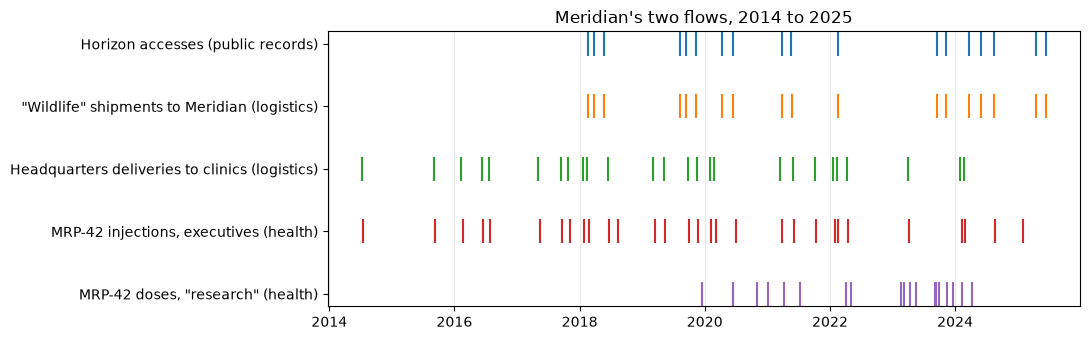

In [12]:
# Biological samples sent from the Meridian warehouses to the headquarters
warehouses = ["FCL-1019", "FCL-1020", "FCL-1024"]
to_headquarters = shipments[shipments["origin_facility_code"].isin(warehouses) & (shipments["destination_facility_code"] == "FCL-1011")
                            & (shipments["item_category"] == "biological_sample")]
print("Biological samples from the warehouses to the headquarters:", len(to_headquarters))
print("First \"wildlife\" shipment:", wildlife["dispatch_time"].min().date(), "| first delivery to the clinics:", deliveries["dispatch_time"].min().date())

# One line per type of event
events = {
    "Horizon accesses (public records)": ends["access_end"],
    "\"Wildlife\" shipments to Meridian (logistics)": wildlife["dispatch_time"],
    "Headquarters deliveries to clinics (logistics)": deliveries["dispatch_time"],
    "MRP-42 injections, executives (health)": executives["day"],
    "MRP-42 doses, \"research\" (health)": mrp.loc[mrp["group"] == "research", "day"],
}
fig, ax = plt.subplots(figsize=(11, 3.5))
for i, (name, dates) in enumerate(events.items()):
    ax.scatter(dates, [i] * len(dates), marker="|", s=300)
ax.set_yticks(range(len(events)))
ax.set_yticklabels(events.keys())
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
ax.set_title("Meridian's two flows, 2014 to 2025")
plt.tight_layout()
plt.show()

The Horizon accesses and the "wildlife" shipments overlap exactly (2018-2025). The deliveries to the clinics and the injections, on the other hand, start **as early as 2014, four years before the first "wildlife" shipment**, and almost no sample goes from the warehouses to the headquarters. So there are **two distinct flows** through Meridian:

1. the bats, from the caves to the warehouses, where they disappear ("consumption");
2. the `MRP-42` product, from the headquarters to the Asterion clinics, for the executives.

*Nothing shows that MRP-42 is made from the bats, as `logistics/02_analysis.ipynb` and `health/03_report.ipynb` also conclude.*

### Step 8: why? A long-term strategy and two camps (public records, ecology)

In [13]:
# The strategy announced in 1962
print("PUB-510033 (1962):", sentence(documents.loc["PUB-510033", "text"], "warming"))
print("                   ", sentence(documents.loc["PUB-510033", "text"], "objected"))

# Mean temperature of the sites per year (2025 is incomplete: January to June only)
climate["year"] = pd.to_datetime(climate["reporting_month"], format="mixed").dt.year
climate["temperature"] = number(climate["mean_temperature_c"])
print("\nMean temperature of the sites:", climate[climate["year"] < 2025].groupby("year")["temperature"].mean().round(2).to_dict())

PUB-510033 (1962): Bell argued that warming trends and expanded flowering corridors would increase the reliability of nocturnal pollination.
                    Vale objected to the proposed industrial concessions, stating that a programme dependent on extraction and permanent heat increase would eventually destroy the habitat it claimed to support.

Mean temperature of the sites: {2019: 26.14, 2020: 26.19, 2021: 26.26, 2022: 26.33, 2023: 26.35, 2024: 26.4}


In [14]:
# Closest public name for each PHENO patient (company officers, authors of memos and documents)
public_names = pd.concat([
    filings[["full_name", "role_title"]].set_axis(["name", "role"], axis=1),
    memos[["author_name", "author_organization"]].set_axis(["name", "role"], axis=1),
    documents[["author_name", "author_organization"]].dropna().set_axis(["name", "role"], axis=1),
]).drop_duplicates("name")
public_names["name"] = public_names["name"].str.replace("Dr. ", "", regex=False)

rows = []
for patient_id in pheno:
    patient_name = patients.loc[patient_id, "given_name"] + " " + patients.loc[patient_id, "family_name"]
    similarity = public_names["name"].apply(lambda n: difflib.SequenceMatcher(None, patient_name.lower(), n.lower()).ratio())
    closest = public_names.loc[similarity.idxmax()]
    rows.append({"patient": patient_id, "patient name": patient_name, "closest public name": closest["name"],
                 "role or organisation": closest["role"], "similarity": round(similarity.max(), 2)})
pd.DataFrame(rows).sort_values("similarity", ascending=False)

,patient,patient name,closest public name,role or organisation,similarity
9,PAT-31086,Niko Veran,Niko Verran,Cold-chain route-planning manager,0.95
5,PAT-31186,Soren Kader,Soren Kade,Strategic logistics director at Meridian BioLo...,0.95
8,PAT-31012,Amara Sen,Amara Senn,Kintara Cave and Pollinator Authority,0.95
3,PAT-31233,Mara Ven,Mara Venn,Former research-logistics employee and indepen...,0.94
2,PAT-31065,Corin Hallen,Corin Hale,Imaging and physiological-signal specialist,0.91
6,PAT-31115,Nadia Oren,Nadia Aren,Maritime operations executive,0.90
1,PAT-31162,Eli Varen,Olia Aren,Policy consultant,0.78
0,PAT-31037,Sel Aran,Selene Aras,Senior ecological analyst,0.74
7,PAT-31040,Jonah Valen,Jonah Bell,Conservation researcher,0.67
4,PAT-31215,Ilan Roe,Miran Soren,Regional executive,0.63


As early as 1962, a group (Jonah Bell, Julien Marot) wants to **warm the climate** to extend night-time blooms, and therefore the bats that pollinate them, and to treat access to the caves as "infrastructure". Jacob Vale objects. The temperature of the sites rises slightly from 2019 to 2024 (+0.26 °C in 6 years), a weak signal.

The two camps still exist: on one side Meridian, Northstar and their allies, on the other Jacob Vale, the Lantern Investigative Bureau and Threshold Earth (`public_records/public_records.ipynb`). The names of several PHENO patients are almost identical to those of members of **both camps**: Soren Kade (Meridian), Niko Verran (Northstar), Nadia Aren (Nivren), Amara Senn (cave authority), but also Mara Venn, the whistleblower. A name resemblance is not proof. The data also contain traps: `PAT-31065` resembles "Corin Hale", whereas the clinical note links them to Elias Voss through other attributes.

## 3. The full story

| Step | What happens | Dataset(s) | What shows it |
|---|---|---|---|
| 1 | Horizon makes 18 night-time accesses to 8 natural sites; afterwards, bats drop by about 59% | public records + ecology | data, placebo test |
| 2 | 6 h after each access, a refrigerated parcel leaves for the Meridian warehouse of the region | public records + logistics | data, 18 out of 18 |
| 3 | Lots disappear from Meridian's stocks, to be "consumed" | logistics + public records | data and documents |
| 4 | Those who consume are a non-human population ("Chamaeleonidian"): two hearts, independent eyes, camouflage; Elias Voss, chairman of Meridian, is one of them | health + public records | data and documents |
| 5 | These beings have lived since at least 1840 under successive identities | public records | data (licenses, mandates) and documents |
| 6 | They buy the protection of 8 human executives by rejuvenating them with MRP-42, delivered by Meridian to the Asterion clinics | health + logistics + public records | data (30 out of 30); the "price of protection" is an interpretation |
| 7 | Their strategy: warm the climate to get more bats; an opposing camp (Jacob Vale) wants to reveal everything | public records + ecology | documents; climate: weak signal |

**In one sentence**: a non-human population, hidden among humans for over a century, feeds on bats captured at night in the caves and orchards, routes them through the company of its leader (Meridian), and secures the silence of human executives by rejuvenating them.

## 4. Limits and open questions

- **Correlation is not causation**: we show systematic coincidences (14 out of 14, 18 out of 18, 30 out of 30), not who decides.
- **The content of MRP-42 is unknown.** Nothing shows that it is made from the bats (step 7).
- **The identities and the non-human nature rest partly on documents**: each document states itself that a resemblance is not proof. The data also contain red herrings ("CHAMELEO" presented as an old dashboard, "Unwabu" as a boat, a capture of bats "for ringing").
- **Still unexplained**: the missing MRP-42 lot no. 1, the invented consultations of 20 June 2025, and the "non-terrestrial transfer" (all the shipment destinations exist in the site register).
- **Few cases** (8 executives, 10 PHENO patients, 18 accesses) and **synthetic data**: the story is fictional.

## 5. Use of generative AI

| Notebook | Where | What is declared |
|---|---|---|
| `public_records/public_records.ipynb` | last cell | occasional help with code formatting and checking the course methods |
| `ecology/ecology.ipynb` | appendix at the end of the notebook | guidelines and proposal of the analysis steps |
| `logistics/02_analysis.ipynb` | under the title | review and correction of the cleaning, restructuring and simplification of the code |
| `health/03_report.ipynb` | first cell | a large part of the code and texts, proposal of methods; choices and validation by the student |
| `00_synthesis.ipynb` | this notebook | writing based on the conclusions of the notebooks; links recomputed and reviewed |